In [2]:
import sys
sys.path.append('../')

import numpy as np
from joblib import Parallel, delayed

from weighted_conformal_clustering.utils import WeightedConformalClustering, gen_moons3, label_alignment

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec

In [3]:
K = 3
n = 600
res = 200

# (name, variance, data seed, clustering random_state)
panels = [('small variance', 1.0, 0, 0),
          ('medium variance', 2.2, 9, 2)]

knn_k = int(np.sqrt(n // 2 / 2))            # kNN classifier
graph_k = int(((n // 2) + 1) * 0.05)        # mutual-kNN graph of the spectral embedding (n_cal + 1 points)

In [4]:
core_hex = {
    3: "#B10DC9",  # purple
    1: "#FDFF8D",  # orange
    2: "#2ECC40",  # green
    0: "#FF810B",  # red
    4: "#64EDFF83",  # blue
}
core_rgb = {k: np.array(mcolors.to_rgb(v), float) for k, v in core_hex.items()}

def darken(rgb, factor=0.15):  # 0.15 = 15% darker
    return np.clip(rgb * (1 - factor), 0, 1)

dark_colors = {k: darken(core_rgb[k], 0.15) for k in core_rgb}
markers = {0: 'x', 1: '^', 2: 'o'}

def lighten_toward_white(rgb, alpha):
    # alpha in [0,1]: 0 = no change, 1 = white
    return (1 - alpha) * rgb + alpha * 1.0

def labels_to_color(labels_like, base_alpha=0.05):
    # mean of the core colours of the labels in the set, moved toward white by base_alpha * (k-1), k = set size
    S = {int(labels_like)} if isinstance(labels_like, (int, np.integer)) else {int(x) for x in labels_like}
    if len(S) == 0:
        return np.array([1.0, 1.0, 1.0], float)   # empty set -> white
    mean_rgb = np.mean([core_rgb[i] for i in S], axis=0)
    return lighten_toward_white(mean_rgb, min(1.0, base_alpha * (len(S) - 1)))

In [6]:
results = []
for name, var, seed, rs in panels:
    X, y = gen_moons3(n_samples=n, noise=var * 0.05, random_state=seed)
    X_tr, y_tr = X[:(n//2)], y[:(n//2)]     # training
    X_cal, y_cal = X[(n//2):n], y[(n//2):n] # calibration
    clst_kwargs = dict(n_neighbors=graph_k, n_components=K, random_state=rs)

    wcc = WeightedConformalClustering(X_tr, X_cal)
    wcc.set_classifier('kNN', n_neighbors=knn_k)
    wcc.train('SpectralGMMS', **clst_kwargs)

    x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
    y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
    X_grid, Y_grid = np.meshgrid(np.linspace(x_min, x_max, res), np.linspace(y_min, y_max, res))
    grid_points = np.column_stack((X_grid.ravel(), Y_grid.ravel()))

    sets = Parallel(n_jobs=-1, verbose=1)(
        delayed(wcc.conformal_set)(grid_points[i].reshape(1, -1), 'SpectralGMMS', **clst_kwargs)
        for i in range(grid_points.shape[0])
    )
    print(f'[{name}] set size counts 0..K: {np.bincount([len(s) for s in sets], minlength=K + 1)}')

    results.append(dict(name=name, X=X, y=y, extent=(x_min, x_max, y_min, y_max), sets=sets,
                        oracle_alignment=label_alignment(y_tr, wcc.y_tr, K)))   # training labels -> true labels (colouring only)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 tasks      | elapsed:    1.8s
[Parallel(n_jobs=-1)]: Done 820 tasks      | elapsed:    3.5s
[Parallel(n_jobs=-1)]: Done 2820 tasks      | elapsed:    7.8s
[Parallel(n_jobs=-1)]: Done 5620 tasks      | elapsed:   14.5s
[Parallel(n_jobs=-1)]: Done 9220 tasks      | elapsed:   24.4s
[Parallel(n_jobs=-1)]: Done 13620 tasks      | elapsed:   35.9s
[Parallel(n_jobs=-1)]: Done 18820 tasks      | elapsed:   49.2s
[Parallel(n_jobs=-1)]: Done 24820 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 31620 tasks      | elapsed:  1.4min
[Parallel(n_jobs=-1)]: Done 39220 tasks      | elapsed:  1.7min
[Parallel(n_jobs=-1)]: Done 40000 out of 40000 | elapsed:  1.7min finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:    0.1s


[small variance] set size counts 0..K: [    0 36297  3687    16]


[Parallel(n_jobs=-1)]: Done 1100 tasks      | elapsed:    2.6s
[Parallel(n_jobs=-1)]: Done 3100 tasks      | elapsed:    7.1s
[Parallel(n_jobs=-1)]: Done 5900 tasks      | elapsed:   14.0s
[Parallel(n_jobs=-1)]: Done 9500 tasks      | elapsed:   23.1s
[Parallel(n_jobs=-1)]: Done 13900 tasks      | elapsed:   34.0s
[Parallel(n_jobs=-1)]: Done 19100 tasks      | elapsed:   47.4s
[Parallel(n_jobs=-1)]: Done 25100 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 31900 tasks      | elapsed:  1.4min
[Parallel(n_jobs=-1)]: Done 39500 tasks      | elapsed:  1.8min


[medium variance] set size counts 0..K: [    0 32972  6584   444]


[Parallel(n_jobs=-1)]: Done 39981 out of 40000 | elapsed:  1.8min remaining:    0.1s
[Parallel(n_jobs=-1)]: Done 40000 out of 40000 | elapsed:  1.8min finished


## Misspecified $K$: medium variance with $K = 2$ and $K = 4$

Same medium-variance setup as above ($\sigma^2 = 2.2$, data seed 9, graph $k = 15$, kNN $k = 12$, clustering `random_state=2`); only `n_components` changes from the true $K = 3$ to $K = 2$ and $K = 4$, in training and in every refit on $\mathcal{D}_{cal} \cup \{x\}$.
If the kNN classifier does not see all $K$ clusters, training is retried with `random_state` 3, 4, ….

Colouring: the $K$ fitted (= classifier) labels are matched to the three true moons by maximum agreement on the training points (assignment on the $K \times 3$ table of counts; for $K = 3$ this is `label_alignment`). With $K = 2$ the cluster that merges two moons takes the colour of the moon it shares most points with; with $K = 4$ the unmatched fitted cluster gets a fourth colour (purple). Points are coloured by their true moon.

In [8]:
from scipy.optimize import linear_sum_assignment

K_misspecified = [2, 4]
name, var, seed, rs = panels[1]             # medium variance
X, y = gen_moons3(n_samples=n, noise=var * 0.05, random_state=seed)
X_tr, y_tr = X[:(n//2)], y[:(n//2)]         # training
X_cal, y_cal = X[(n//2):n], y[(n//2):n]     # calibration

x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
X_grid, Y_grid = np.meshgrid(np.linspace(x_min, x_max, res), np.linspace(y_min, y_max, res))
grid_points = np.column_stack((X_grid.ravel(), Y_grid.ravel()))

def colour_map(y_true, y_fit, K_fit):
    # fitted label -> colour key, by maximum agreement with the true labels; unmatched fitted labels get keys 3, 4
    C = np.zeros((K_fit, K))
    np.add.at(C, (y_fit, y_true), 1)
    rows, cols = linear_sum_assignment(-C)
    cmap = np.full(K_fit, -1)
    cmap[rows] = cols
    extra = iter(range(K, len(core_hex)))
    for j in range(K_fit):
        if cmap[j] < 0:
            cmap[j] = next(extra)
    return cmap

results_misK = {}
for K_fit in K_misspecified:
    clst_kwargs = dict(n_neighbors=graph_k, n_components=K_fit, random_state=rs)

    wcc = WeightedConformalClustering(X_tr, X_cal)
    wcc.set_classifier('kNN', n_neighbors=knn_k)
    for rs_tr in range(rs, rs + 50):
        try:
            wcc.train('SpectralGMMS', **{**clst_kwargs, 'random_state': rs_tr})
            break
        except ValueError:
            continue

    sets = Parallel(n_jobs=-1, verbose=1)(
        delayed(wcc.conformal_set)(grid_points[i].reshape(1, -1), 'SpectralGMMS', **clst_kwargs)
        for i in range(grid_points.shape[0])
    )
    cmap = colour_map(y_tr, wcc.y_tr, K_fit)
    print(f'[K = {K_fit}] training random_state {rs_tr}; fitted label -> colour {cmap}; '
          f'set size counts 0..K: {np.bincount([len(s) for s in sets], minlength=K_fit + 1)}')
    results_misK[K_fit] = dict(sets=sets, colour_map=cmap)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 1100 tasks      | elapsed:    2.2s
[Parallel(n_jobs=-1)]: Done 3100 tasks      | elapsed:    7.0s
[Parallel(n_jobs=-1)]: Done 5900 tasks      | elapsed:   13.3s
[Parallel(n_jobs=-1)]: Done 9500 tasks      | elapsed:   21.5s
[Parallel(n_jobs=-1)]: Done 13900 tasks      | elapsed:   31.3s
[Parallel(n_jobs=-1)]: Done 19100 tasks      | elapsed:   42.4s
[Parallel(n_jobs=-1)]: Done 25100 tasks      | elapsed:   55.9s
[Parallel(n_jobs=-1)]: Done 31900 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done 39500 tasks      | elapsed:  1.6min
[Parallel(n_jobs=-1)]: Done 39981 out of 40000 | elapsed:  1.6min remaining:    0.0s
[Parallel(n_jobs=-1)]: Done 40000 out of 40000 | elapsed:  1.6min finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.


[K = 2] training random_state 2; fitted label -> colour [0 2]; set size counts 0..K: [    0 37060  2940]


[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 1100 tasks      | elapsed:    3.2s
[Parallel(n_jobs=-1)]: Done 3100 tasks      | elapsed:    9.2s
[Parallel(n_jobs=-1)]: Done 5900 tasks      | elapsed:   18.0s
[Parallel(n_jobs=-1)]: Done 9500 tasks      | elapsed:   30.8s
[Parallel(n_jobs=-1)]: Done 13900 tasks      | elapsed:   50.4s
[Parallel(n_jobs=-1)]: Done 19100 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done 25100 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done 31900 tasks      | elapsed:  1.9min
[Parallel(n_jobs=-1)]: Done 39500 tasks      | elapsed:  2.4min


[K = 4] training random_state 2; fitted label -> colour [0 1 2 3]; set size counts 0..K: [    0 34118  5830    52     0]


[Parallel(n_jobs=-1)]: Done 39981 out of 40000 | elapsed:  2.4min remaining:    0.1s
[Parallel(n_jobs=-1)]: Done 40000 out of 40000 | elapsed:  2.4min finished


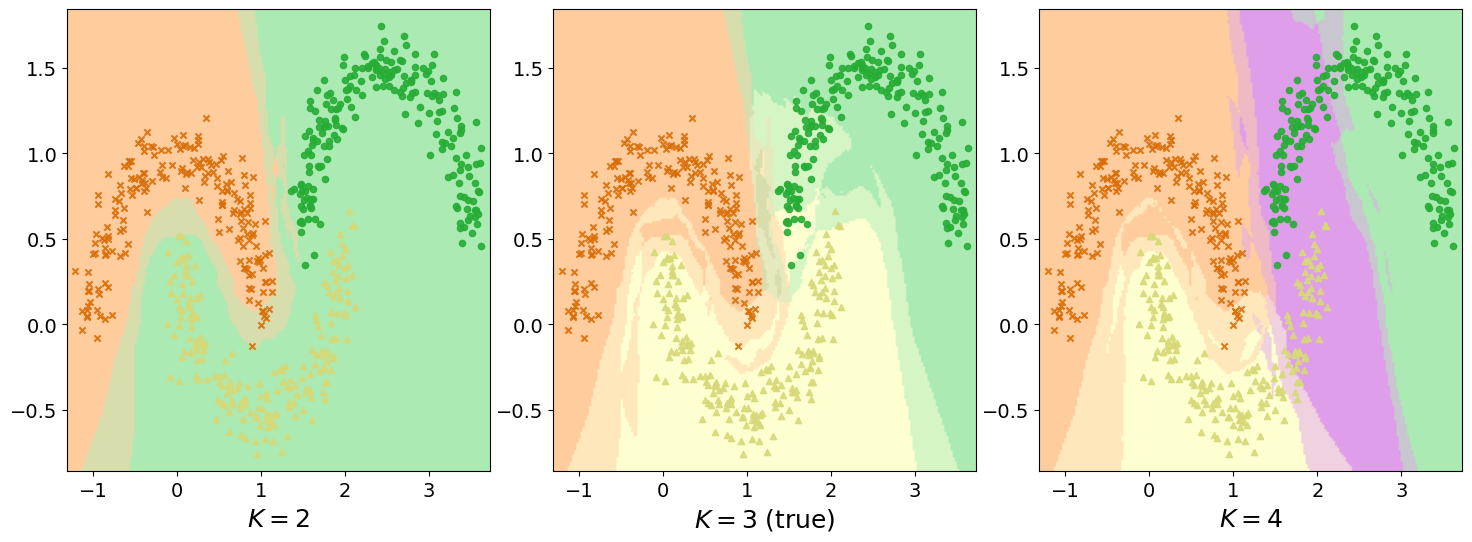

In [ ]:
med = next(r for r in results if r['name'] == 'medium variance')       # true K = 3, computed above
panels_misK = [(2, results_misK[2]['sets'], results_misK[2]['colour_map']),
               (3, med['sets'], med['oracle_alignment']),
               (4, results_misK[4]['sets'], results_misK[4]['colour_map'])]

fig = plt.figure(figsize=(18, 6))
gs = GridSpec(nrows=1, ncols=3, figure=fig, wspace=0.15, hspace=0.2)
X, y = med['X'], med['y']
x_min, x_max, y_min, y_max = med['extent']

for c, (K_fit, sets, cmap) in enumerate(panels_misK):
    ax = fig.add_subplot(gs[0, c])
    color_grid = np.array([labels_to_color(cmap[s]) for s in sets]).reshape((res, res, 3))
    ax.imshow(color_grid, origin='lower', extent=(x_min, x_max, y_min, y_max), aspect='auto', alpha=0.4)
    for label in range(K):
        mask = (y == label)
        ax.scatter(X[mask, 0], X[mask, 1], color=dark_colors[label], s=20, alpha=0.9, marker=markers[label])
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)
    ax.annotate(f'$K = {K_fit}$' + (' (true)' if K_fit == K else ''), xy=(0.5, -0.12), xycoords='axes fraction',
                ha='center', fontsize=18, color='black')

#plt.savefig('Moon2D3_medium_misspecifiedK_heatmaps.pdf', bbox_inches='tight')
plt.show()

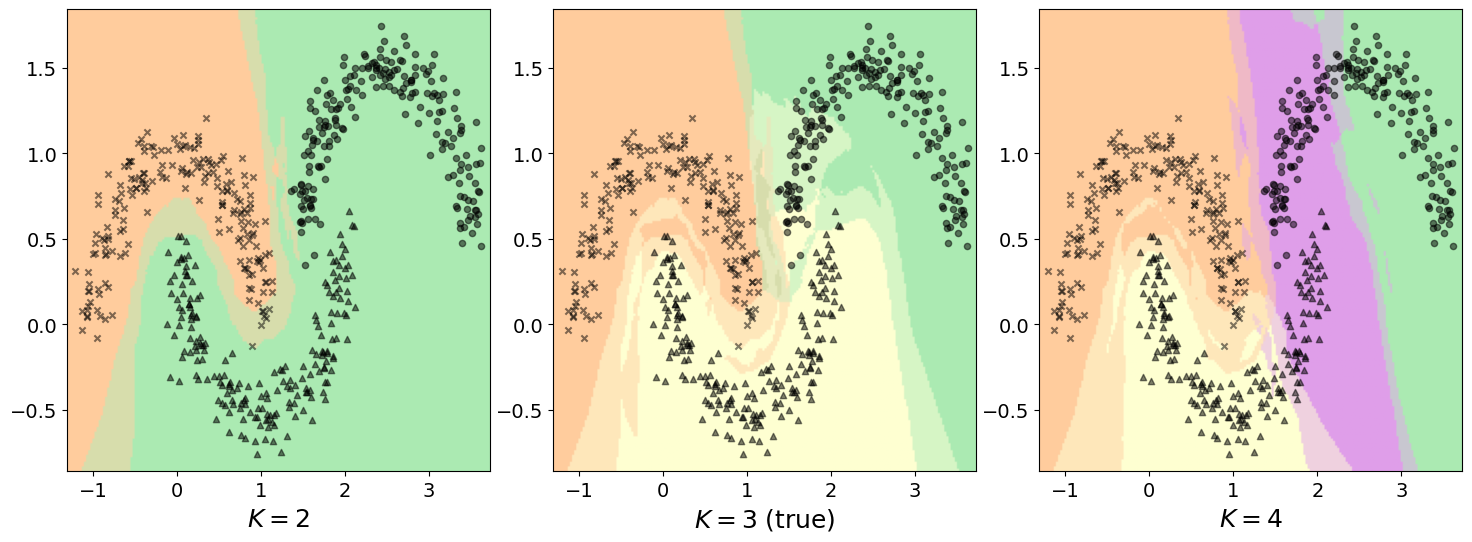

In [9]:
med = next(r for r in results if r['name'] == 'medium variance')       # true K = 3, computed above
panels_misK = [(2, results_misK[2]['sets'], results_misK[2]['colour_map']),
               (3, med['sets'], med['oracle_alignment']),
               (4, results_misK[4]['sets'], results_misK[4]['colour_map'])]

fig = plt.figure(figsize=(18, 6))
gs = GridSpec(nrows=1, ncols=3, figure=fig, wspace=0.15, hspace=0.2)
X, y = med['X'], med['y']
x_min, x_max, y_min, y_max = med['extent']

for c, (K_fit, sets, cmap) in enumerate(panels_misK):
    ax = fig.add_subplot(gs[0, c])
    color_grid = np.array([labels_to_color(cmap[s]) for s in sets]).reshape((res, res, 3))
    ax.imshow(color_grid, origin='lower', extent=(x_min, x_max, y_min, y_max), aspect='auto', alpha=0.4)
    for label in range(K):
        mask = (y == label)
        ax.scatter(X[mask, 0], X[mask, 1], color='black', s=20, alpha=0.5, marker=markers[label])
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)
    ax.annotate(f'$K = {K_fit}$' + (' (true)' if K_fit == K else ''), xy=(0.5, -0.12), xycoords='axes fraction',
                ha='center', fontsize=18, color='black')

plt.savefig('Figures/Moon2D3_heatmaps_misspecified.pdf', bbox_inches='tight')
plt.show()